In [18]:
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd



10.0 inferences took 70.0 us
100.0 inferences took 695.0 us
1000.0 inferences took 6938.0 us
10000.0 inferences took 68182.0 us
100000.0 inferences took 681813.0 us


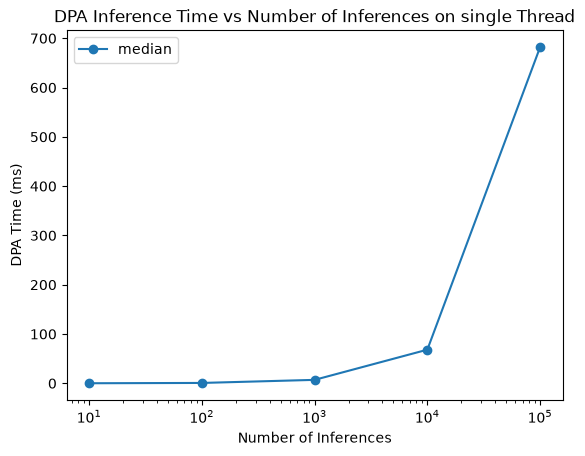

In [20]:
NUM_INFERENCES = [10, 100, 1000, 10000, 100000]

df = pd.read_csv("nn_inference_series.csv")
inferences = []
dpa_time_us = []
for num_inferences in NUM_INFERENCES:
    df_filtered = df[df['inferences'] == num_inferences].median()
    print(f"{df_filtered['inferences']} inferences took {df_filtered['dpa_time_us']} us")
    inferences.append(df_filtered['inferences'])
    dpa_time_us.append(df_filtered['dpa_time_us']/1000)
plt.plot(inferences, dpa_time_us, marker='o', label="median")
plt.xscale('log')
plt.xlabel('Number of Inferences')
plt.ylabel('DPA Time (ms)')
plt.title('DPA Inference Time vs Number of Inferences on single Thread')
plt.legend()
plt.show()

In [ ]:
df_mt = pd.read_csv("nn_same_core.csv")
runs = df_mt.groupby(["threads", "run"]).first().reset_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(runs["threads"], runs["threads"] * runs["inferences"] / (runs["makespan_us"] * 1e-6), "o")
ax1.set_xlabel("Threads auf einem DPA-Kern")
ax1.set_ylabel("Inferenzen/s gesamt")
ax2.plot(df_mt["threads"], df_mt["dpa_time_us"] / df_mt["inferences"], "o")
ax2.set_xlabel("Threads auf einem DPA-Kern")
ax2.set_ylabel("Zeit pro Inferenz je Modell (µs)")
plt.tight_layout()
plt.savefig("nn_same_core.pdf")
plt.savefig("nn_same_core.png", dpi=200)
plt.show()